<a href="https://colab.research.google.com/github/srihanreddy/Quantum-Hackathon/blob/main/Continuous_Distribution_Quantum_GAN.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Continuous-Distribution Quantum GAN (QGAN)
**Kaggle-ready experiment | Classical GAN vs Hybrid Quantum-Classical GAN**

This notebook learns two one-dimensional continuous distributions:
- **D25:** one-dimensional Gaussian mixture (synthetic)
- **D36:** Beta(2,5) continuous samples (synthetic)

Metrics: Wasserstein-1 distance, RBF-kernel MMD, moment error, and mode coverage.
Quantum resource accounting: qubits, circuit depth, shots, circuit evaluations, training time, and generation time.

**Method note:** The QGAN in this notebook is a hybrid *qubit-based* generator. A variational circuit maps latent noise to expectation values; a small classical affine output layer maps those values to the target range. The discriminator is classical. This is a practical continuous-output adaptation for this project, not a claim to reproduce every architecture in the cited survey.

## 1. Setup and reproducibility
If Kaggle has internet enabled, install PennyLane. Restart the session only if Kaggle requests it.

In [1]:
%pip install -q pennylane

In [2]:
import os, time, math, json, random, platform
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.utils.data import DataLoader, TensorDataset
import pennylane as qml

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

DEVICE = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")
print("Python:", platform.python_version())
print("PyTorch:", torch.__version__)
print("PennyLane:", qml.__version__)
print("PyTorch device:", DEVICE)
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

OUT = Path("/kaggle/working/qgan_results") if Path("/kaggle/working").exists() else Path("./qgan_results")
OUT.mkdir(parents=True, exist_ok=True)

# Start with these modest settings; increase epochs after the first successful run.
N_REAL = 2048
BATCH_SIZE = 64
EPOCHS = 60
LATENT_DIM = 2
N_QUBITS = 2
Q_DEPTH = 2
Q_SHOTS = None  # analytic training; finite-shot evaluation is a separate diagnostic
LR_G = 2e-4
LR_D = 2e-4

Python: 3.13.16
PyTorch: 2.14.1+cu130
PennyLane: 0.45.1
PyTorch device: cuda:0
GPU: Tesla T4


## 2. Generate continuous datasets
The random generator is seeded for repeatability. The Gaussian mixture is a three-mode 1D distribution; Beta(2,5) is supported on [0,1].

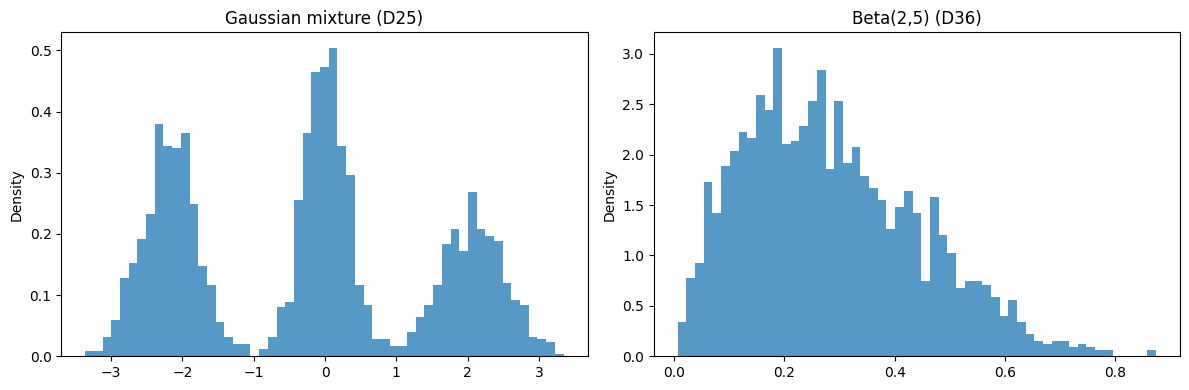

Data generation time: 0.0028s


In [3]:
rng = np.random.default_rng(SEED)

def make_gaussian_mixture(n, rng):
    # Three Gaussian modes with unequal weights.
    weights = np.array([0.35, 0.40, 0.25])
    means = np.array([-2.2, 0.0, 2.1])
    stds = np.array([0.38, 0.32, 0.45])
    component = rng.choice(len(weights), size=n, p=weights)
    return rng.normal(means[component], stds[component]).astype(np.float32)

def make_beta_25(n, rng):
    return rng.beta(2.0, 5.0, size=n).astype(np.float32)

generation_start = time.perf_counter()
DATASETS = {
    "Gaussian mixture (D25)": make_gaussian_mixture(N_REAL, rng),
    "Beta(2,5) (D36)": make_beta_25(N_REAL, rng),
}
data_generation_seconds = time.perf_counter() - generation_start

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, (name, values) in zip(axes, DATASETS.items()):
    ax.hist(values, bins=55, density=True, alpha=0.75)
    ax.set_title(name)
    ax.set_ylabel("Density")
plt.tight_layout()
plt.show()
print(f"Data generation time: {data_generation_seconds:.4f}s")

## 3. Train/test split and scaling
Use a reproducible shuffled split because these are independently generated IID samples, not time series. The generator is trained on the training partition only; metrics are computed against held-out real samples.

In [4]:
def split_and_scale(values, seed=SEED):
    values = np.asarray(values, dtype=np.float32)
    perm = np.random.default_rng(seed).permutation(len(values))
    n_train = int(0.8 * len(values))
    train_raw, test_raw = values[perm[:n_train]], values[perm[n_train:]]
    lo, hi = float(train_raw.min()), float(train_raw.max())
    # Robust fixed scaling bounds derived from training data; clipping is recorded by using same transform at test.
    pad = 0.05 * (hi - lo + 1e-8)
    lo, hi = lo - pad, hi + pad
    train_scaled = 2.0 * (train_raw - lo) / (hi - lo) - 1.0
    test_scaled = 2.0 * (test_raw - lo) / (hi - lo) - 1.0
    return train_scaled.astype(np.float32), test_scaled.astype(np.float32), (lo, hi)

SPLITS = {name: split_and_scale(values, SEED+i) for i, (name, values) in enumerate(DATASETS.items())}
for name, (tr, te, bounds) in SPLITS.items():
    print(name, "train:", tr.shape, "test:", te.shape, "scaling bounds:", bounds)

Gaussian mixture (D25) train: (1638,) test: (410,) scaling bounds: (-3.693534791969574, 3.5510308151476746)
Beta(2,5) (D36) train: (1638,) test: (410,) scaling bounds: (-0.03729243624198336, 0.9183776816463758)


## 4. Models
The classical baseline is an MLP generator and MLP discriminator. The QGAN generator uses a 2-qubit variational circuit and a classical affine readout; its discriminator is the same classical architecture as the baseline. PennyLane's `default.qubit` simulator is CPU-based; PyTorch discriminator and classical baseline use the selected CUDA device when available.

In [5]:
class ClassicalGenerator(nn.Module):
    def __init__(self, latent_dim=LATENT_DIM):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(latent_dim, 32), nn.LeakyReLU(0.2),
            nn.Linear(32, 32), nn.LeakyReLU(0.2),
            nn.Linear(32, 1), nn.Tanh()
        )
    def forward(self, z):
        return self.net(z)

class Discriminator(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(1, 32), nn.LeakyReLU(0.2),
            nn.Linear(32, 32), nn.LeakyReLU(0.2),
            nn.Linear(32, 1)
        )
    def forward(self, x):
        return self.net(x)

qdev = qml.device("default.qubit", wires=N_QUBITS, shots=Q_SHOTS)

@qml.qnode(qdev, interface="torch", diff_method="backprop")
def q_generator_circuit(z, weights):
    qml.AngleEmbedding(z, wires=range(N_QUBITS), rotation="Y")
    qml.StronglyEntanglingLayers(weights, wires=range(N_QUBITS))
    return tuple(qml.expval(qml.PauliZ(w)) for w in range(N_QUBITS))

class QuantumGenerator(nn.Module):
    def __init__(self):
        super().__init__()
        # Keep circuit parameters on CPU because default.qubit is a CPU simulator.
        self.q_weights = nn.Parameter(0.01 * torch.randn(Q_DEPTH, N_QUBITS, 3))
        # Keep the quantum circuit parameters on CPU, but accelerate the
        # classical measurement-to-output readout on the selected PyTorch device.
        self.readout = nn.Linear(N_QUBITS, 1).to(DEVICE)
    def forward(self, z):
        z_cpu = z.to(device="cpu", dtype=torch.float32)
        q_out = q_generator_circuit(z_cpu, self.q_weights)
        if isinstance(q_out, tuple):
            features = torch.stack(q_out, dim=-1)
        else:
            features = q_out
        features = features.to(device=z.device, dtype=torch.float32)
        return torch.tanh(self.readout(features))

print("Quantum circuit depth (PennyLane estimate):", qml.specs(q_generator_circuit)(
    torch.zeros(LATENT_DIM), torch.zeros(Q_DEPTH, N_QUBITS, 3)
)["resources"].depth)

Quantum circuit depth (PennyLane estimate): 2


## 5. Training utilities
We use the non-saturating GAN objective with logits and `BCEWithLogitsLoss`. One discriminator update and one generator update are performed per minibatch. The QGAN quantum circuit is analytic during training (`shots=None`); finite-shot effects are measured later as a separate resource/noise diagnostic.

In [6]:
bce = nn.BCEWithLogitsLoss()

def train_gan(train_values, quantum=False, epochs=EPOCHS):
    G = QuantumGenerator() if quantum else ClassicalGenerator()
    D = Discriminator().to(DEVICE)
    if not quantum:
        G = G.to(DEVICE)
    optG = torch.optim.Adam(G.parameters(), lr=LR_G, betas=(0.5, 0.999))
    optD = torch.optim.Adam(D.parameters(), lr=LR_D, betas=(0.5, 0.999))
    loader = DataLoader(
        TensorDataset(torch.tensor(train_values.reshape(-1, 1), dtype=torch.float32)),
        batch_size=BATCH_SIZE, shuffle=True, drop_last=True
    )
    history = {"d_loss": [], "g_loss": []}
    start = time.perf_counter()
    circuit_calls = 0

    for epoch in range(epochs):
        d_running, g_running, n_batches = 0.0, 0.0, 0
        for (real_cpu,) in loader:
            real = real_cpu.to(DEVICE)
            bs = real.shape[0]

            # Discriminator step
            optD.zero_grad(set_to_none=True)
            z = torch.rand(bs, LATENT_DIM, device=DEVICE) * (2*np.pi) - np.pi
            with torch.no_grad():
                fake = G(z)
            real_logits = D(real)
            fake_logits = D(fake.detach())
            d_loss = bce(real_logits, torch.ones_like(real_logits)) + bce(
                fake_logits, torch.zeros_like(fake_logits)
            )
            d_loss.backward()
            optD.step()

            # Generator step
            optG.zero_grad(set_to_none=True)
            z = torch.rand(bs, LATENT_DIM, device=DEVICE) * (2*np.pi) - np.pi
            fake = G(z)
            fake_logits = D(fake)
            g_loss = bce(fake_logits, torch.ones_like(fake_logits))
            g_loss.backward()
            optG.step()

            if quantum:
                # Two generator calls per minibatch; each circuit is batch-broadcast if supported.
                circuit_calls += 2 * bs
            d_running += float(d_loss.detach().cpu())
            g_running += float(g_loss.detach().cpu())
            n_batches += 1

        history["d_loss"].append(d_running / max(n_batches, 1))
        history["g_loss"].append(g_running / max(n_batches, 1))

    if DEVICE.type == "cuda":
        torch.cuda.synchronize()
    elapsed = time.perf_counter() - start
    return G, D, history, elapsed, circuit_calls

def generate_samples(generator, n, quantum=False, batch_size=128):
    generator.eval()
    outputs = []
    start = time.perf_counter()
    with torch.no_grad():
        remaining = n
        while remaining > 0:
            bs = min(batch_size, remaining)
            z = torch.rand(bs, LATENT_DIM, device=DEVICE) * (2*np.pi) - np.pi
            out = generator(z)
            outputs.append(out.detach().cpu().numpy().reshape(-1))
            remaining -= bs
    if DEVICE.type == "cuda":
        torch.cuda.synchronize()
    elapsed = time.perf_counter() - start
    return np.concatenate(outputs), elapsed

## 6. Evaluation metrics
- **Wasserstein-1:** empirical 1D earth-mover distance.
- **MMD:** biased empirical maximum mean discrepancy with an RBF kernel; bandwidth is the median pairwise distance heuristic.
- **Moment error:** absolute difference in mean and standard deviation, reported separately and summed.
- **Mode coverage:** fraction of the three known Gaussian-mixture modes receiving at least one generated sample within a fixed neighbourhood. For Beta(2,5), report coverage of five equal-width support bins instead (this is a support-bin diagnostic, not a true mode count).

In [7]:
def mmd_rbf(x, y):
    x = np.asarray(x, dtype=np.float64).reshape(-1, 1)
    y = np.asarray(y, dtype=np.float64).reshape(-1, 1)
    combined = np.vstack([x, y])
    # Deterministic subsample for bandwidth estimate if arrays are large.
    sample = combined[::max(1, len(combined)//500)]
    d2 = ((sample[:, None, :] - sample[None, :, :])**2).sum(-1)
    positive = d2[d2 > 0]
    sigma2 = np.median(positive) if positive.size else 1.0
    gamma = 1.0 / max(2.0 * sigma2, 1e-8)
    kxx = np.exp(-gamma * ((x[:,None,:]-x[None,:,:])**2).sum(-1))
    kyy = np.exp(-gamma * ((y[:,None,:]-y[None,:,:])**2).sum(-1))
    kxy = np.exp(-gamma * ((x[:,None,:]-y[None,:,:])**2).sum(-1))
    return float(kxx.mean() + kyy.mean() - 2*kxy.mean())

def evaluate_distribution(real, fake, dataset_name):
    from scipy.stats import wasserstein_distance
    w1 = float(wasserstein_distance(real, fake))
    mmd = mmd_rbf(real, fake)
    mean_error = float(abs(np.mean(real) - np.mean(fake)))
    std_error = float(abs(np.std(real) - np.std(fake)))
    if "Gaussian mixture" in dataset_name:
        centers = np.array([-2.2, 0.0, 2.1])
        covered = [np.any(np.abs(fake-c) < 0.65) for c in centers]
        coverage = float(np.mean(covered))
        coverage_label = "3-mode coverage"
    else:
        edges = np.linspace(0.0, 1.0, 6)
        counts, _ = np.histogram(fake, bins=edges)
        coverage = float(np.mean(counts > 0))
        coverage_label = "5-bin support coverage"
    return {
        "Wasserstein_1": w1,
        "MMD_RBF": mmd,
        "mean_error": mean_error,
        "std_error": std_error,
        "total_moment_error": mean_error + std_error,
        "mode_or_support_coverage": coverage,
        "coverage_definition": coverage_label
    }

## 7. Run both models on both distributions
This is the main experiment. If the QGAN is slow on Kaggle CPU simulation, first smoke-test with `EPOCHS=5` and `N_REAL=512`, then restore the full settings.

In [8]:
all_results = []
trained = {}
training_histories = {}
generated = {}

for ds_index, (name, (train_scaled, test_scaled, bounds)) in enumerate(SPLITS.items()):
    print("\n==========", name, "==========")
    for model_name, quantum in [("Classical GAN", False), ("Quantum GAN", True)]:
        print(f"Training {model_name} ...")
        G, D, hist, train_seconds, circuit_calls = train_gan(train_scaled, quantum=quantum)
        fake_scaled, generation_seconds = generate_samples(G, len(test_scaled), quantum=quantum)

        lo, hi = bounds
        real_original = (test_scaled + 1.0) * 0.5 * (hi - lo) + lo
        fake_original = (fake_scaled + 1.0) * 0.5 * (hi - lo) + lo

        metrics = evaluate_distribution(real_original, fake_original, name)
        row = {
            "dataset": name,
            "model": model_name,
            **metrics,
            "training_seconds": train_seconds,
            "generation_seconds_for_test_size": generation_seconds,
            "generated_samples_per_second": len(fake_scaled) / max(generation_seconds, 1e-9),
            "quantum_circuit_evaluations_proxy": circuit_calls if quantum else 0
        }
        all_results.append(row)
        trained[(name, model_name)] = (G, D)
        training_histories[(name, model_name)] = hist
        generated[(name, model_name)] = fake_original
        print(row)

results_df = pd.DataFrame(all_results)
display(results_df)


========== Gaussian mixture (D25) ==========
Training Classical GAN ...
{'dataset': 'Gaussian mixture (D25)', 'model': 'Classical GAN', 'Wasserstein_1': 0.3729294082013573, 'MMD_RBF': 0.01888773145871281, 'mean_error': 0.32842281460762024, 'std_error': 0.014717578887939453, 'total_moment_error': 0.3431403934955597, 'mode_or_support_coverage': 1.0, 'coverage_definition': '3-mode coverage', 'training_seconds': 9.367312339000023, 'generation_seconds_for_test_size': 0.0014521779999654427, 'generated_samples_per_second': 282334.53475383646, 'quantum_circuit_evaluations_proxy': 0}
Training Quantum GAN ...
{'dataset': 'Gaussian mixture (D25)', 'model': 'Quantum GAN', 'Wasserstein_1': 0.38519446064786217, 'MMD_RBF': 0.013020511444994387, 'mean_error': 0.016005299985408783, 'std_error': 0.24486351013183594, 'total_moment_error': 0.2608688101172447, 'mode_or_support_coverage': 1.0, 'coverage_definition': '3-mode coverage', 'training_seconds': 43.06964800200001, 'generation_seconds_for_test_size

,dataset,model,Wasserstein_1,MMD_RBF,mean_error,std_error,total_moment_error,mode_or_support_coverage,coverage_definition,training_seconds,generation_seconds_for_test_size,generated_samples_per_second,quantum_circuit_evaluations_proxy
0,Gaussian mixture (D25),Classical GAN,0.372929,0.018888,0.328423,0.014718,0.343140,1.0,3-mode coverage,9.367312,0.001452,282334.534754,0
1,Gaussian mixture (D25),Quantum GAN,0.385194,0.013021,0.016005,0.244864,0.260869,1.0,3-mode coverage,43.069648,0.024935,16442.823690,192000
2,"Beta(2,5) (D36)",Classical GAN,0.055059,0.016762,0.055059,0.025540,0.080599,0.8,5-bin support coverage,8.227618,0.001342,305456.344339,0
3,"Beta(2,5) (D36)",Quantum GAN,0.017418,0.002473,0.008077,0.007462,0.015539,0.8,5-bin support coverage,34.352009,0.031926,12842.016170,192000


## 8. Visualizations

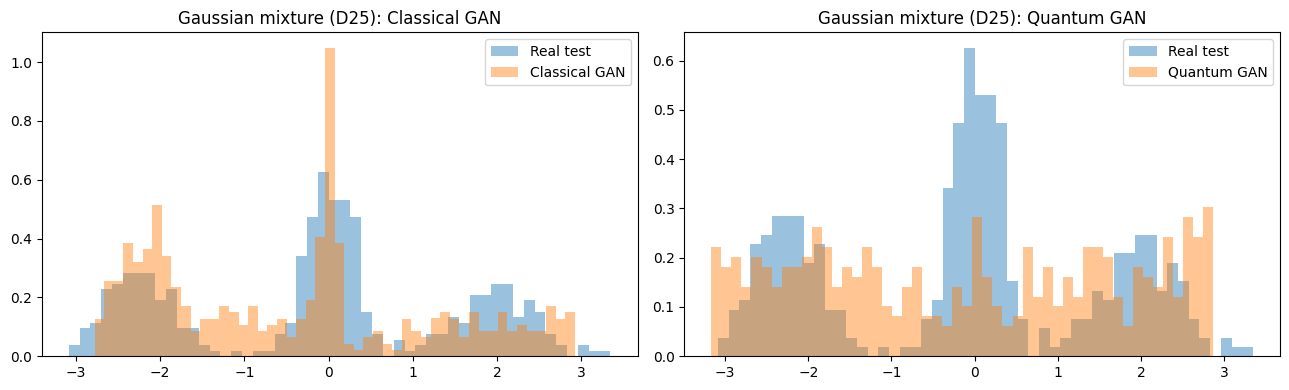

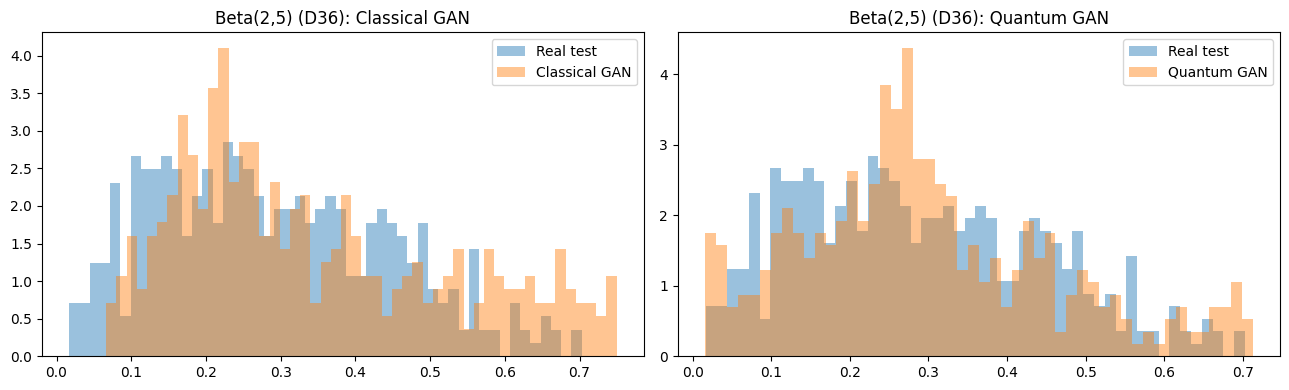

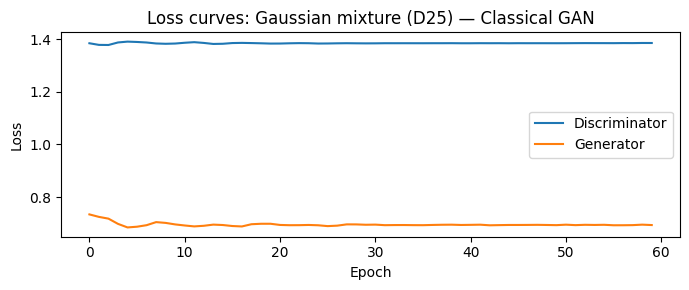

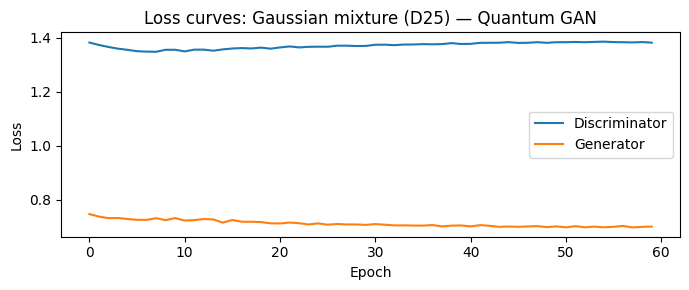

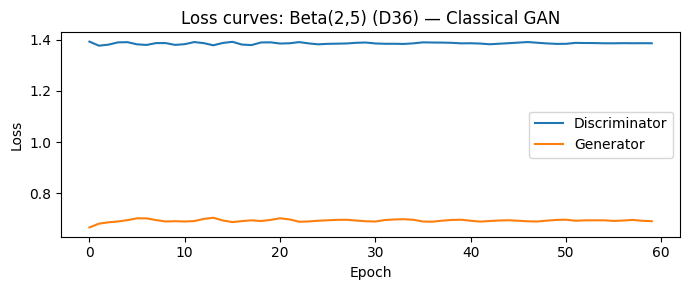

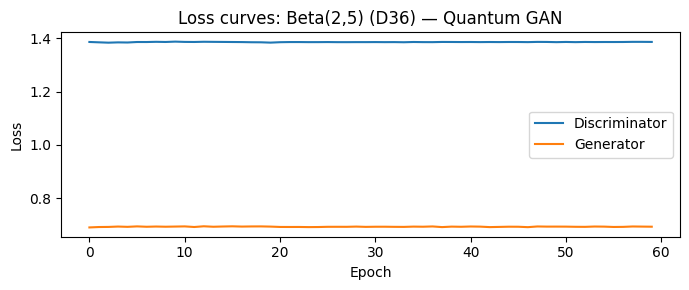

In [9]:
for name, (train_scaled, test_scaled, bounds) in SPLITS.items():
    lo, hi = bounds
    real_original = (test_scaled + 1.0) * 0.5 * (hi - lo) + lo
    fig, axes = plt.subplots(1, 2, figsize=(13, 4))
    for ax, model_name in zip(axes, ["Classical GAN", "Quantum GAN"]):
        fake = generated[(name, model_name)]
        ax.hist(real_original, bins=50, density=True, alpha=0.45, label="Real test")
        ax.hist(fake, bins=50, density=True, alpha=0.45, label=model_name)
        ax.set_title(f"{name}: {model_name}")
        ax.legend()
    plt.tight_layout()
    plt.show()

for key, hist in training_histories.items():
    plt.figure(figsize=(7,3))
    plt.plot(hist["d_loss"], label="Discriminator")
    plt.plot(hist["g_loss"], label="Generator")
    plt.title(f"Loss curves: {key[0]} — {key[1]}")
    plt.xlabel("Epoch")
    plt.ylabel("Loss")
    plt.legend()
    plt.tight_layout()
    plt.show()

## 9. Quantum resource accounting
Circuit depth is obtained from PennyLane resource specifications. The circuit-evaluation count is a transparent proxy based on the number of generated latent samples passed through the quantum generator during both discriminator and generator updates. It is not a hardware job count and may differ from low-level device executions due to simulator batching/gradient implementation.

In [11]:
spec = qml.specs(q_generator_circuit)(
    torch.zeros(LATENT_DIM),
    torch.zeros(Q_DEPTH, N_QUBITS, 3)
)

# Extract resources from CircuitSpecs object
resource_obj = spec.resources

circuit_depth = getattr(resource_obj, "depth", None)
gate_count = getattr(resource_obj, "num_gates", None)

quantum_rows = []

for row in all_results:
    if row["model"] == "Quantum GAN":

        quantum_rows.append({
            "dataset": row["dataset"],
            "qubits": N_QUBITS,
            "modes": "N/A (qubit-based circuit)",
            "variational_layers": Q_DEPTH,
            "circuit_depth": circuit_depth,
            "gate_count": gate_count,
            "shots_training": "analytic (shots=None)",
            "finite_shots_diagnostic": "see Section 10",
            "circuit_evaluations_proxy": row["quantum_circuit_evaluations_proxy"],
            "training_seconds": row["training_seconds"],
            "generation_seconds": row["generation_seconds_for_test_size"],
            "generation_samples_per_second": row["generated_samples_per_second"]
        })

quantum_resources_df = pd.DataFrame(quantum_rows)

display(quantum_resources_df)

,dataset,qubits,modes,variational_layers,circuit_depth,gate_count,shots_training,finite_shots_diagnostic,circuit_evaluations_proxy,training_seconds,generation_seconds,generation_samples_per_second
0,Gaussian mixture (D25),2,N/A (qubit-based circuit),2,2,2,analytic (shots=None),see Section 10,192000,43.069648,0.024935,16442.82369
1,"Beta(2,5) (D36)",2,N/A (qubit-based circuit),2,2,2,analytic (shots=None),see Section 10,192000,34.352009,0.031926,12842.01617


## 10. Finite-shot measurement diagnostic
The training experiment uses analytic expectations for stable differentiable optimization. This section evaluates the same trained quantum circuit with finite shots to estimate sampling noise in the circuit outputs. It does not retrain the GAN with finite shots.

In [12]:
finite_shot_rows = []
if len(quantum_resources_df):
    qdev_shot = qml.device("default.qubit", wires=N_QUBITS, shots=256)

    @qml.qnode(qdev_shot, interface="torch", diff_method=None)
    def q_generator_finite_shot(z, weights):
        qml.AngleEmbedding(z, wires=range(N_QUBITS), rotation="Y")
        qml.StronglyEntanglingLayers(weights, wires=range(N_QUBITS))
        return tuple(qml.expval(qml.PauliZ(w)) for w in range(N_QUBITS))

    for name in SPLITS:
        G, _ = trained[(name, "Quantum GAN")]
        weights = G.q_weights.detach().cpu()
        z_test = torch.linspace(-np.pi, np.pi, steps=32).reshape(16,2)
        analytic_values, sampled_values = [], []
        for z in z_test:
            analytic = q_generator_circuit(z, weights)
            sampled = q_generator_finite_shot(z, weights)
            analytic_values.append(torch.stack(analytic).detach().numpy())
            sampled_values.append(torch.stack(sampled).detach().numpy())
        analytic_values = np.asarray(analytic_values)
        sampled_values = np.asarray(sampled_values)
        finite_shot_rows.append({
            "dataset": name,
            "shots": 256,
            "latent_inputs_tested": len(z_test),
            "mean_absolute_expectation_deviation": float(np.mean(np.abs(analytic_values-sampled_values))),
            "max_absolute_expectation_deviation": float(np.max(np.abs(analytic_values-sampled_values))),
            "circuit_evaluations": len(z_test)
        })

finite_shot_df = pd.DataFrame(finite_shot_rows)
display(finite_shot_df)

/usr/local/lib/python3.13/dist-packages/pennylane/devices/device_api.py:207: PennyLaneDeprecationWarning: Setting shots on device is deprecated. Please use the `set_shots` transform on the respective QNode instead.
  warnings.warn(


,dataset,shots,latent_inputs_tested,mean_absolute_expectation_deviation,max_absolute_expectation_deviation,circuit_evaluations
0,Gaussian mixture (D25),256,16,0.023256,0.066252,16
1,"Beta(2,5) (D36)",256,16,0.033586,0.112838,16


## 11. Export experiment outputs

In [13]:
results_df.to_csv(OUT / "distribution_metrics.csv", index=False)
quantum_resources_df.to_csv(OUT / "quantum_resources.csv", index=False)
finite_shot_df.to_csv(OUT / "finite_shot_diagnostic.csv", index=False)

summary = {
    "seed": SEED,
    "n_real_samples_per_dataset": N_REAL,
    "batch_size": BATCH_SIZE,
    "epochs": EPOCHS,
    "latent_dim": LATENT_DIM,
    "n_qubits": N_QUBITS,
    "q_depth": Q_DEPTH,
    "training_shots": Q_SHOTS,
    "pytorch_device": str(DEVICE),
    "data_generation_seconds": data_generation_seconds,
    "results": all_results
}
with open(OUT / "experiment_summary.json", "w") as f:
    json.dump(summary, f, indent=2)

print("Saved outputs to:", OUT)
print(sorted(p.name for p in OUT.iterdir()))

Saved outputs to: qgan_results
['distribution_metrics.csv', 'experiment_summary.json', 'finite_shot_diagnostic.csv', 'quantum_resources.csv']


## 12. Interpretation checklist
When interpreting results, do not assume the QGAN is better merely because it is quantum. Compare the metrics:
- Lower Wasserstein-1 and MMD indicate closer distribution matching.
- Lower moment error indicates better mean/standard-deviation matching.
- Higher mode coverage is desirable for the Gaussian mixture; higher support-bin coverage is desirable for Beta(2,5).
- Training and generation time reveal practical computational cost.
- The finite-shot diagnostic quantifies measurement noise separately from analytic training.

**Limitations:** The experiment uses a small 2-qubit simulator and a classical discriminator. It does not establish quantum advantage. The quantum circuit is simulated on CPU with `default.qubit`; CUDA accelerates the classical PyTorch components only. The circuit-evaluation count is a proxy, and finite-shot results are diagnostic rather than a finite-shot-trained QGAN.

## References
1. Islam, M., Turkeli, S., & Ozaydin, F. (2026). *Quantum generative adversarial networks: architectures, use cases, and real-world implementations*. Quantum Information Processing, 25, 11. https://doi.org/10.1007/s11128-025-05044-6
2. PennyLane, *Quantum GANs* tutorial: https://pennylane.ai/demos/tutorial_quantum_gans/
3. NumPy Generator documentation: https://numpy.org/doc/stable/reference/random/generator.html